In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
columns = [
    'checking_account', 'duration', 'credit_history',
    'purpose', 'credit_amount', 'savings',
    'employment', 'installment_rate', 'personal_status',
    'other_debtors', 'residence', 'property',
    'age', 'other_installment_plans', 'housing',
    'existing_credits', 'job', 'dependents',
    'telephone', 'foreign_worker', 'credit_risk'
]

df = pd.read_csv(
    '/content/german.data',
    sep=' ',
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,checking_account,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column information
print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_account         1000 non-null   object
 1   duration                 1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings                  1000 non-null   object
 6   employment               1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status          1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence                1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   objec

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
checking_account           0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings                    0
employment                 0
installment_rate           0
personal_status            0
other_debtors              0
residence                  0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
dependents                 0
telephone                  0
foreign_worker             0
credit_risk                0
dtype: int64

Duplicate Records: 0


credit_risk
1    700
2    300
Name: count, dtype: int64


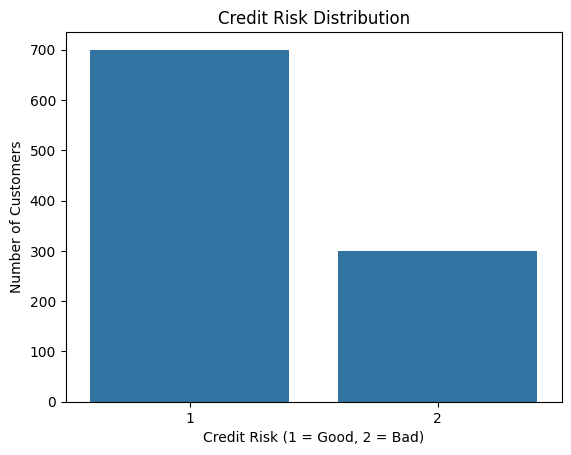

In [5]:
# Count credit risk categories
print(df['credit_risk'].value_counts())

# Visualize credit risk
sns.countplot(x='credit_risk', data=df)

plt.title('Credit Risk Distribution')
plt.xlabel('Credit Risk (1 = Good, 2 = Bad)')
plt.ylabel('Number of Customers')
plt.show()

In [6]:
df['credit_risk'] = df['credit_risk'].map({1: 1, 2: 0})

print(df['credit_risk'].value_counts())

credit_risk
1    700
0    300
Name: count, dtype: int64


In [7]:
X = df.drop('credit_risk', axis=1)
y = df['credit_risk']

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (1000, 20)
Target variable: (1000,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 20)
Testing data: (200, 20)


In [9]:
print("Categorical Columns:")
print(X.select_dtypes(include='object').columns.tolist())

print("\nNumerical Columns:")
print(X.select_dtypes(include=['int64', 'float64']).columns.tolist())

Categorical Columns:
['checking_account', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

Numerical Columns:
['duration', 'credit_amount', 'installment_rate', 'residence', 'age', 'existing_credits', 'dependents']


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = X.select_dtypes(include='object').columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


In [11]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (800, 20)
Processed training shape: (800, 61)

Original testing shape: (200, 20)
Processed testing shape: (200, 61)


In [12]:
# Import machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Create models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train all models
for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [13]:
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test_processed)

print("Predictions completed successfully!")

Predictions completed successfully!


In [14]:
from sklearn.metrics import accuracy_score

results = []

for name, model in models.items():
    y_pred = predictions[name]

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': accuracy * 100
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy
0  Logistic Regression      70.5
1        Decision Tree      67.5
2        Random Forest      74.5


In [15]:
from sklearn.metrics import classification_report

for name, model in models.items():
    print("\n", "="*40)
    print(name)
    print("="*40)

    y_pred = model.predict(X_test_processed)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['Bad Credit', 'Good Credit']
    ))


Logistic Regression
              precision    recall  f1-score   support

  Bad Credit       0.51      0.45      0.48        60
 Good Credit       0.78      0.81      0.79       140

    accuracy                           0.70       200
   macro avg       0.64      0.63      0.64       200
weighted avg       0.70      0.70      0.70       200


Decision Tree
              precision    recall  f1-score   support

  Bad Credit       0.46      0.48      0.47        60
 Good Credit       0.77      0.76      0.77       140

    accuracy                           0.68       200
   macro avg       0.62      0.62      0.62       200
weighted avg       0.68      0.68      0.68       200


Random Forest
              precision    recall  f1-score   support

  Bad Credit       0.60      0.43      0.50        60
 Good Credit       0.78      0.88      0.83       140

    accuracy                           0.74       200
   macro avg       0.69      0.66      0.67       200
weighted avg       0.73

Logistic Regression


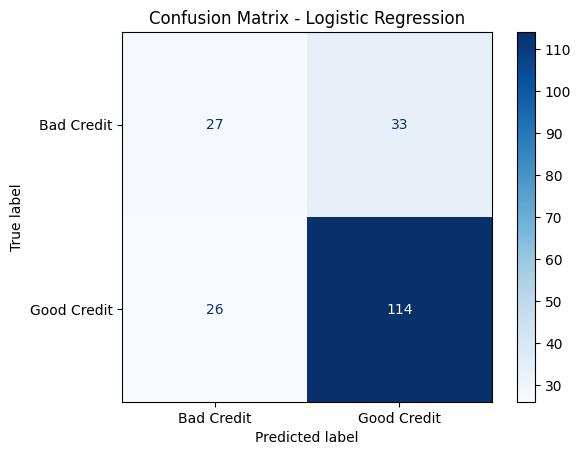

Decision Tree


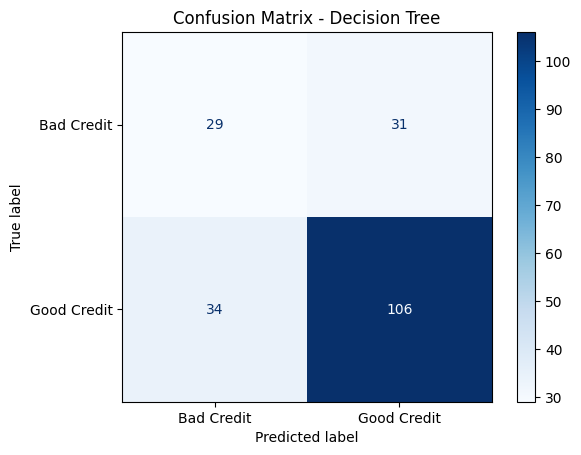

Random Forest


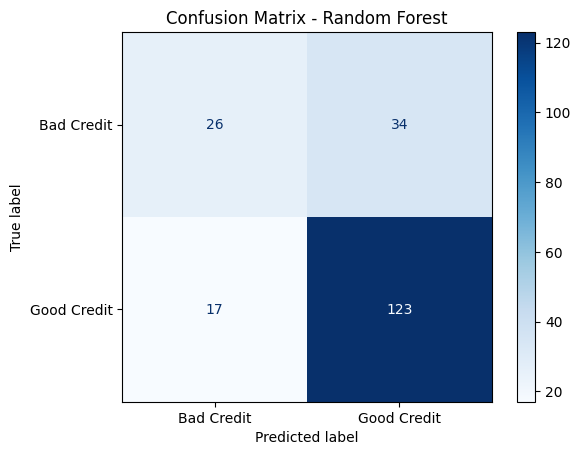

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    print(name)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Bad Credit', 'Good Credit']
    )

    disp.plot(cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

In [17]:
from sklearn.metrics import roc_auc_score

for name, model in models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    auc = roc_auc_score(y_test, y_prob)

    print(name, "ROC-AUC Score:", round(auc, 3))

Logistic Regression ROC-AUC Score: 0.759
Decision Tree ROC-AUC Score: 0.62
Random Forest ROC-AUC Score: 0.785


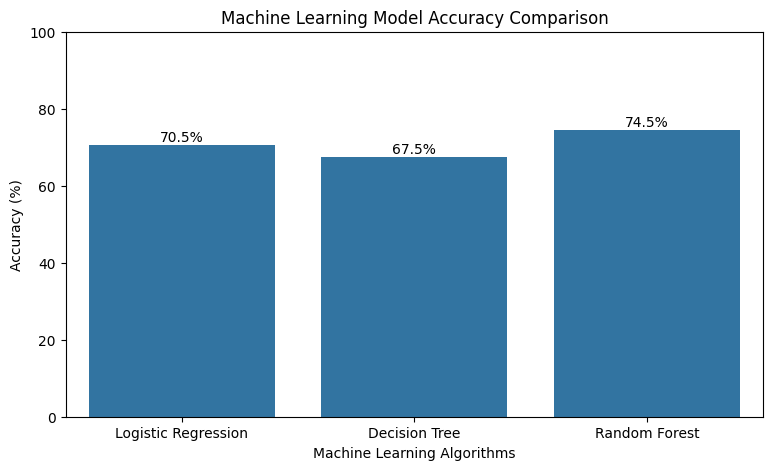

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

for i, value in enumerate(results_df['Accuracy']):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.show()

In [19]:
best_model_name = results_df.loc[
    results_df['Accuracy'].idxmax(), 'Model'
]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best Accuracy:",
      results_df['Accuracy'].max(), "%")

Best Model: Random Forest
Best Accuracy: 74.5 %


In [20]:
import joblib

joblib.dump(best_model, 'credit_scoring_model.pkl')

joblib.dump(preprocessor, 'credit_preprocessor.pkl')

print("Model saved successfully!")

Model saved successfully!


In [21]:
from google.colab import files

files.download('credit_scoring_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
files.download('credit_preprocessor.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
files.download('german.data')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>